# 02. Preparação do texto e divisão entre treino e teste

**Universidade Presbiteriana Mackenzie** · Tecnologia em Banco de Dados · Projeto Aplicado II  
**Grupo Drop Table:** Igor Eduardo Dallan do Couto (RA 10748144), Jaqueline de Oliveira Alves (RA 10755023), Kayo Oliveira Nukui (RA 10356420) e Lucas de Lima Mendes (RA 10756562)  
**Empresa fictícia:** ConectaShop  
**Responsável por este notebook:** Lucas de Lima Mendes

Este notebook transforma o arquivo bruto de avaliações nos conjuntos usados pelos modelos. Ele mostra, passo a passo, o que o script `src/preparacao.py` faz, e no final confere se o resultado é igual ao do script. As funções de normalização e divisão são importadas de `src/`, então existe uma única versão da regra.

**Entrada:** `data/raw/olist_order_reviews_dataset.csv`
**Saídas (em `data/processed/`):** `avaliacoes_preparadas.csv`, `treino.csv`, `teste.csv` e `relatorio_preparacao.json`

## 1. Decisões de preparação

1. **Avaliações sem texto saem.** O classificador aprende com o que o cliente escreveu; uma avaliação só com nota não tem o que ensinar.
2. **Título e mensagem viram um texto só.** Muitos clientes escrevem o essencial no título ("Não recebi").
3. **Normalização leve.** Letras minúsculas; URLs, e-mails e números viram marcadores (`url`, `email`, `numero`); pontuação sai. Acentos e palavras de negação ficam.
4. **Textos com rótulos conflitantes saem.** Se o mesmo texto aparece com nota 1 e com nota 5, ele ensinaria duas respostas opostas.
5. **Duplicatas saem antes da divisão.** Se a mesma frase ficasse no treino e no teste, o teste mediria memória, e não generalização.
6. **Divisão 80/20 estratificada, com semente fixa.** A proporção das classes fica igual nos dois conjuntos, e a divisão pode ser repetida.

### Bibliotecas utilizadas neste notebook

| Biblioteca | O que faz | Por que usamos neste notebook |
|---|---|---|
| `pandas` | Estrutura de dados em tabela (DataFrame) e leitura de CSV | Ler o CSV bruto, limpar e dividir a base em treino e teste |
| `matplotlib` | Biblioteca de gráficos de baixo nível | Gráfico de barras da distribuição das classes |

In [ ]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Permite rodar o notebook a partir da pasta notebooks/ ou da raiz do projeto
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE_DIR))

from src.preparacao import MAPA_SENTIMENTO, normalizar_texto, dividir_base, preparar_avaliacoes

plt.style.use("seaborn-v0_8-whitegrid")

## 2. Leitura do arquivo bruto

In [ ]:
caminho_bruto = BASE_DIR / "data" / "raw" / "olist_order_reviews_dataset.csv"
if not caminho_bruto.exists():
    raise FileNotFoundError(f"Arquivo bruto não encontrado: {caminho_bruto}")

df_bruto = pd.read_csv(caminho_bruto, low_memory=False)
print(f"Linhas no arquivo bruto: {len(df_bruto):,}")
df_bruto.dtypes

Linhas no arquivo bruto: 99,224


review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment_message       str
review_creation_date         str
review_answer_timestamp      str
dtype: object

## 3. Colunas usadas e valores ausentes

Ficamos só com as colunas necessárias: identificadores, nota, título e mensagem.

In [ ]:
colunas = ["review_id", "order_id", "review_score", "review_comment_title", "review_comment_message"]
df = df_bruto[colunas].copy()

ausentes = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "ausentes_%": (df.isna().mean() * 100).round(2),
})
ausentes

,ausentes,ausentes_%
review_id,0,0.00
order_id,0,0.00
review_score,0,0.00
review_comment_title,87656,88.34
review_comment_message,58247,58.70


## 4. Normalização e rótulo de sentimento

A função `normalizar_texto` vem de `src/preparacao.py`. Veja um exemplo antes de aplicar na base inteira:

In [ ]:
exemplo = "Produto NÃO chegou!!! Comprei 2 unidades, veja em www.loja.com.br"
print("Original:   ", exemplo)
print("Normalizado:", normalizar_texto(exemplo))

Original:    Produto NÃO chegou!!! Comprei 2 unidades, veja em www.loja.com.br
Normalizado: produto não chegou comprei numero unidades veja em url


In [ ]:
df["review_score"] = pd.to_numeric(df["review_score"], errors="coerce")
df = df[df["review_score"].isin(MAPA_SENTIMENTO)].copy()

df["texto_original"] = (
    df["review_comment_title"].fillna("").astype(str).str.strip()
    + " "
    + df["review_comment_message"].fillna("").astype(str).str.strip()
).str.strip()
df["texto_limpo"] = df["texto_original"].map(normalizar_texto)
df["sentimento"] = df["review_score"].astype(int).map(MAPA_SENTIMENTO)

sem_texto = int(df["texto_limpo"].eq("").sum())
df = df[df["texto_limpo"].ne("")].copy()
print(f"Sem texto útil (descartadas): {sem_texto:,}")
print(f"Com texto útil:               {len(df):,}")

Sem texto útil (descartadas): 56,656
Com texto útil:               42,568


## 5. Rótulos conflitantes e duplicatas

Primeiro removemos todos os textos que aparecem com mais de um sentimento. Depois, entre os que sobraram, mantemos uma única cópia de cada texto.

In [ ]:
sentimentos_por_texto = df.groupby("texto_limpo")["sentimento"].nunique()
textos_conflitantes = set(sentimentos_por_texto[sentimentos_por_texto > 1].index)
linhas_conflitantes = int(df["texto_limpo"].isin(textos_conflitantes).sum())
conflitantes_frequentes = df.loc[df["texto_limpo"].isin(textos_conflitantes), "texto_limpo"].value_counts().head(10)
df = df[~df["texto_limpo"].isin(textos_conflitantes)].copy()

antes = len(df)
df = df.drop_duplicates(subset=["texto_limpo", "sentimento"], keep="first").copy()
duplicatas = antes - len(df)

print(f"Linhas com rótulo conflitante (descartadas): {linhas_conflitantes:,}")
print(f"Duplicatas removidas:                        {duplicatas:,}")
print(f"Base preparada:                              {len(df):,}")
print("\nTextos conflitantes mais frequentes (linhas):")
print(conflitantes_frequentes.to_string())

Linhas com rótulo conflitante (descartadas): 5,169
Duplicatas removidas:                        2,501
Base preparada:                              34,898

Textos conflitantes mais frequentes (linhas):
texto_limpo
muito bom          559
recomendo          421
bom                405
ótimo              302
excelente          267
otimo              259
super recomendo    153
ok                 130
boa                118
tudo ok            111


**Leitura.** Os textos conflitantes mais comuns são elogios curtos, como "muito bom", "recomendo" e "ok". Eles aparecem com notas altas e baixas porque, sozinhos, dizem pouco sobre a experiência do cliente. Tirá-los deixa a supervisão mais limpa, com o custo de perder alguns exemplos.

## 6. Distribuição das classes na base preparada

,avaliacoes,proporcao_%
sentimento,,
positivo,21488,61.57
negativo,10245,29.36
neutro,3165,9.07


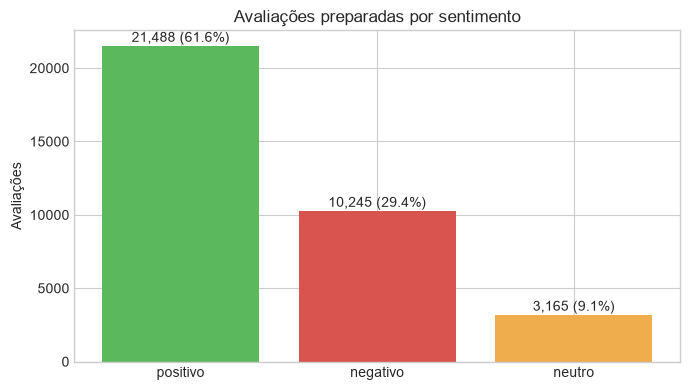

In [ ]:
colunas_finais = ["review_id", "order_id", "review_score", "sentimento", "texto_original", "texto_limpo"]
df_final = df[colunas_finais].sort_values(["sentimento", "review_id"]).reset_index(drop=True)

contagem = df_final["sentimento"].value_counts()
proporcao = (df_final["sentimento"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"avaliacoes": contagem, "proporcao_%": proporcao}))

cores = {"positivo": "#5cb85c", "negativo": "#d9534f", "neutro": "#f0ad4e"}
plt.figure(figsize=(7, 4))
plt.bar(contagem.index, contagem.values, color=[cores[c] for c in contagem.index])
for i, (n, p) in enumerate(zip(contagem.values, proporcao.values)):
    plt.text(i, n + 300, f"{n:,} ({p:.1f}%)", ha="center")
plt.title("Avaliações preparadas por sentimento")
plt.ylabel("Avaliações")
plt.tight_layout()
plt.show()

**Leitura.** Entre as avaliações com texto, cerca de 62% são positivas, 29% negativas e 9% neutras. A classe neutra é pequena e, como veremos no notebook 04, é a mais difícil de acertar.

## 7. Divisão entre treino e teste

Usamos `dividir_base` de `src/preparacao.py`: 20% para teste, estratificado por sentimento, semente 42. Em seguida verificamos se algum texto limpo aparece nos dois conjuntos.

Uma observação sobre essa verificação: ela compara o texto limpo, que ainda tem acentos. O vetorizador do notebook 03 remove acentos, então frases curtas como "ótimo tudo certo" e "otimo tudo certo" chegam iguais ao modelo mesmo estando em conjuntos diferentes. O notebook 04 mede esse efeito, que é pequeno.

In [ ]:
treino, teste = dividir_base(df_final, proporcao_teste=0.20, semente=42)
interseccao = set(treino["texto_limpo"]) & set(teste["texto_limpo"])

print(f"Treino: {len(treino):,} ({len(treino) / len(df_final):.0%})")
print(f"Teste:  {len(teste):,} ({len(teste) / len(df_final):.0%})")
print(f"Textos limpos presentes nos dois conjuntos: {len(interseccao)}")
display(pd.DataFrame({
    "treino_%": (treino["sentimento"].value_counts(normalize=True) * 100).round(2),
    "teste_%": (teste["sentimento"].value_counts(normalize=True) * 100).round(2),
}))

if interseccao:
    raise ValueError("Há textos idênticos em treino e teste.")

Treino: 27,918 (80%)
Teste:  6,980 (20%)
Textos limpos presentes nos dois conjuntos: 0


,treino_%,teste_%
sentimento,,
positivo,61.57,61.58
negativo,29.36,29.36
neutro,9.07,9.07


## 8. Conferência com o script e gravação

Rodamos `preparar_avaliacoes` sobre o mesmo arquivo e comparamos com o resultado deste notebook. Se forem iguais, gravamos os arquivos em `data/processed/`. O conteúdo gravado é o mesmo que `python -m src.preparacao` produz.

In [ ]:
df_script, resumo = preparar_avaliacoes(df_bruto)
pd.testing.assert_frame_equal(df_final, df_script)
print("O notebook e src/preparacao.py produzem a mesma base.")

dir_saida = BASE_DIR / "data" / "processed"
dir_saida.mkdir(parents=True, exist_ok=True)
df_final.to_csv(dir_saida / "avaliacoes_preparadas.csv", index=False, encoding="utf-8")
treino.to_csv(dir_saida / "treino.csv", index=False, encoding="utf-8")
teste.to_csv(dir_saida / "teste.csv", index=False, encoding="utf-8")

resumo.update({
    "linhas_treino": len(treino),
    "linhas_teste": len(teste),
    "proporcao_teste": 0.20,
    "semente_aleatoria": 42,
    "sobreposicao_textual_treino_teste": len(interseccao),
})
(dir_saida / "relatorio_preparacao.json").write_text(
    json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(resumo, ensure_ascii=False, indent=2))

O notebook e src/preparacao.py produzem a mesma base.
{
  "linhas_originais": 99224,
  "linhas_sem_texto": 56656,
  "linhas_com_texto_ambiguo": 5169,
  "duplicatas_textuais_removidas": 2501,
  "linhas_preparadas": 34898,
  "distribuicao_sentimentos": {
    "positivo": 21488,
    "negativo": 10245,
    "neutro": 3165
  },
  "linhas_treino": 27918,
  "linhas_teste": 6980,
  "proporcao_teste": 0.2,
  "semente_aleatoria": 42,
  "sobreposicao_textual_treino_teste": 0
}


## 9. Resumo

| Etapa | Linhas removidas | Linhas restantes |
|---|---|---|
| Arquivo bruto | | 99.224 |
| Sem texto útil | 56.656 | 42.568 |
| Rótulo conflitante | 5.169 | 37.399 |
| Duplicatas | 2.501 | 34.898 |
| Treino / teste | | 27.918 / 6.980 |

Atenção à leitura do número final: 34.898 não é o total de avaliações com comentário (são 40.977 com mensagem), e sim o que sobra depois da limpeza. Próximo passo: notebook 03, que compara classificadores usando `treino.csv`.